# Multivariable calculus 6: Vector fields and line integrals

*Learning path: multivariable calculus, part 6 of 7.* [Index](README.md) · Previous: [Multiple integrals](05-multiple-integrals.ipynb) · Next: [The big theorems](07-the-big-theorems.ipynb)

Push a box up a ramp, or carry it up the stairs: gravity takes the same work back either way, because only the
height matters. Drag the same box across a rough floor along a winding path, and friction takes more work the longer
the path. What is the difference between these two kinds of force, mathematically? This lesson answers with
**vector fields**, **line integrals** and **potentials**.

**Who this is for.** You know gradients ([lesson 2](02-partial-derivatives-and-gradient.ipynb)), the chain rule along
a path (lesson 2, section 6), and parametrized curves ([foundations 9](../foundations/09-geometry-and-conics.ipynb)).
Physics students will recognise work and potential energy; nobody needs them.

**What you will be able to do afterwards:**

1. draw and read a vector field;
2. compute the work of a field along a path, and the length of a curve, as line integrals;
3. decide whether a field is conservative (a gradient), find its potential, and use it to compute work in one step;
4. explain why the test $\partial P/\partial y = \partial Q/\partial x$ can fail on a region with a hole.

Plan about an hour.

## 1. Vector fields

A **vector field** attaches a vector to every point: the wind at each place on a weather map, the velocity of water
in a river, the force on a charge. In the plane it is $F(x, y) = [P(x, y), Q(x, y)]$. Draw three:

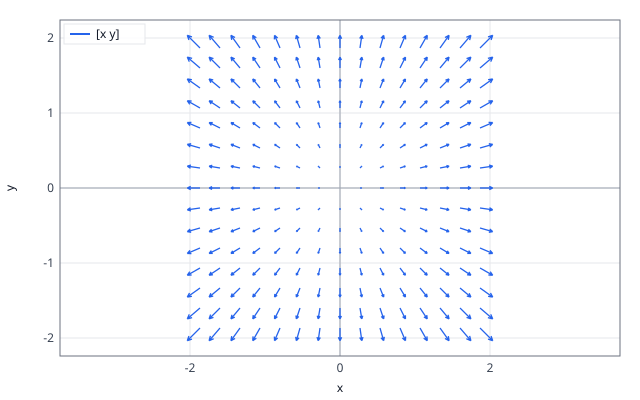

> Each arrow shows the field at the middle of its cell: its direction, and its length relative to the longest arrow.

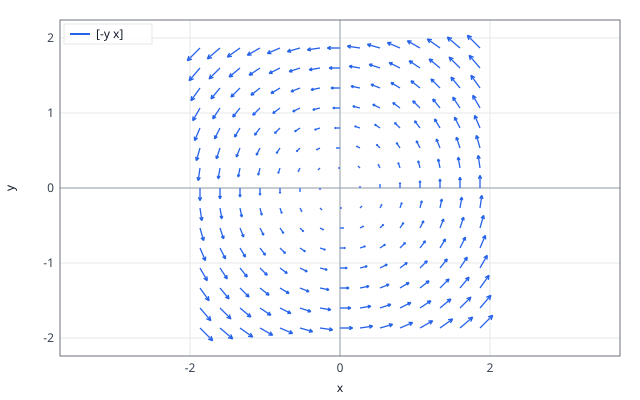

> Each arrow shows the field at the middle of its cell: its direction, and its length relative to the longest arrow.

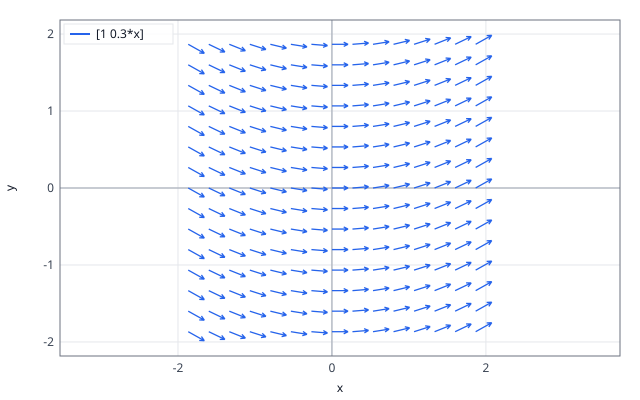

> Each arrow shows the field at the middle of its cell: its direction, and its length relative to the longest arrow.

In [1]:
fieldplot([x, y], x, -2, 2, y, -2, 2)
fieldplot([-y, x], x, -2, 2, y, -2, 2)
fieldplot([1, 0.3*x], x, -2, 2, y, -2, 2)

How to read the call: `fieldplot([P Q], x, from, to, y, from, to)` draws the vector $[P, Q]$ at the middle of each
cell, scaled so that the longest arrow just fits. The first field points away from the origin and grows with
distance: a **source**. The second turns around the origin: a **vortex**, like water draining from a bath. The third
is a flow to the right with a shear.

**Try this.** Predict what $[y, x]$ looks like before drawing it. (Hint: on the line $y = x$ the arrows point along
the line; on $y = -x$?)

## 2. Work along a path

A force $F$ moves an object along a path $r(t) = [x(t), y(t)]$, $a \le t \le b$. Over a tiny step $dr = r'(t)\,dt$
the work is $F \cdot dr$: only the part of the force along the motion counts. Add up:

$$W = \int_C F\cdot dr = \int_a^b F(r(t)) \cdot r'(t)\,dt.$$

Work of the vortex $F = [-y, x]$ once around the unit circle $r(t) = [\cos t, \sin t]$. By hand:
$F(r(t)) = [-\sin t, \cos t]$, $r'(t) = [-\sin t, \cos t]$, their dot product is $\sin^2 t + \cos^2 t = 1$, and
$W = \int_0^{2\pi} 1\,dt = 2\pi$.

In [2]:
lineint([-y, x], [x y], [cos(t), sin(t)], t, 0, 2*pi)

2*pi

> The work ∫ F · dr: along the path, F · r'(t) = 1, integrated over t from 0 to 2*pi. For a gradient field it depends only on the end points.

How to read the call: `lineint(F, [x y], [x(t) y(t)], t, a, b)`: the field in the variables $x, y$, then the path
in terms of $t$, then the range of $t$. The note shows the integrand $F(r(t))\cdot r'(t)$ that Galileo built, so you
can compare it with yours. The vortex pushes along the circle all the way, so it does positive work: $2\pi$.

The same command with a scalar instead of a field integrates $f\,ds$ along the curve, with $ds = |r'(t)|\,dt$. With
$f = 1$ it gives the **length**:

In [3]:
lineint(1, [x y], [R*cos(t), R*sin(t)], t, 0, 2*pi)

2*pi*R

> The integral ∫ f ds of a scalar along the path, with ds = |r'(t)| dt: integrand R over t from 0 to 2*pi. With f = 1 it is the length of the curve.

**Try this.** Compute by hand the work of the source $F = [x, y]$ around the unit circle. Then check. Why is the
answer what it is? (Look at the angle between $F$ and $r'$.)

## 3. Does the path matter?

Take $F = [2xy, x^2 + 3y^2]$ and two paths from $(0, 0)$ to $(1, 1)$: the straight line and the parabola $y = x^2$.

In [4]:
F = [2*x*y, x^2 + 3*y^2]
lineint(F, [x y], [t, t], t, 0, 1)
lineint(F, [x y], [t, t^2], t, 0, 1)

[2*x*y, x^2+3*y^2]

2

> The work ∫ F · dr: along the path, F · r'(t) = 6*t^2, integrated over t from 0 to 1. For a gradient field it depends only on the end points.

2

> The work ∫ F · dr: along the path, F · r'(t) = 6*t^5+4*t^3, integrated over t from 0 to 1. For a gradient field it depends only on the end points.

Both give 2. Try a third, crazier path, out along the $x$-axis and back up:

In [5]:
lineint(F, [x y], [t, 0], t, 0, 1) + lineint(F, [x y], [1, t], t, 0, 1)

2

> The work ∫ F · dr: along the path, F · r'(t) = 0, integrated over t from 0 to 1. For a gradient field it depends only on the end points.
>
> The work ∫ F · dr: along the path, F · r'(t) = 3*t^2+1, integrated over t from 0 to 1. For a gradient field it depends only on the end points.

Still 2. And for the vortex? From $(1, 0)$ to $(-1, 0)$ along the upper half circle and along the lower half:

In [6]:
lineint([-y, x], [x y], [cos(t), sin(t)], t, 0, pi)
lineint([-y, x], [x y], [cos(t), -sin(t)], t, 0, pi)

pi

> The work ∫ F · dr: along the path, F · r'(t) = 1, integrated over t from 0 to pi. For a gradient field it depends only on the end points.

-pi

> The work ∫ F · dr: along the path, F · r'(t) = -1, integrated over t from 0 to pi. For a gradient field it depends only on the end points.

$\pi$ and $-\pi$: here the path matters. The first field behaves like gravity; the second, like the wind around a
storm, does not. What makes the difference?

## 4. Conservative fields and potentials

Suppose $F = \nabla\varphi$ for some function $\varphi$, a **potential**. Then along any path, by the chain rule
(lesson 2, section 6),

$$\int_C \nabla\varphi\cdot dr = \int_a^b \frac{d}{dt}\varphi(r(t))\,dt = \varphi(\text{end}) - \varphi(\text{start}).$$

This is the **fundamental theorem for line integrals**: the work only depends on the end points. Such a field is
called **conservative** (energy is conserved; $-\varphi$ is the potential energy in physics). For our $F$:

In [7]:
phi = potential(F, [x y])
grad(phi, [x y])

x^2*y+y^3

> A potential φ has grad φ = F, so the work of F along any path is φ(end) − φ(start): the field is conservative. Found by integrating the first component in its variable and fixing what the other components still need. Any constant can be added.

[2*x*y, x^2+3*y^2]

> The gradient lists the partial derivatives [∂f/∂x, ∂f/∂y]. It points in the direction in which f increases fastest, its length is that fastest rate, and it is perpendicular to the level curves (or surfaces) of f.

$\varphi = x^2 y + y^3$, and $\varphi(1, 1) - \varphi(0, 0) = 2$: the work along every path, in one step. How
`potential` finds it, which you can do by hand: integrate $P = 2xy$ in $x$ to get $x^2 y + g(y)$; then
$\partial/\partial y$ of that must equal $Q$: $x^2 + g'(y) = x^2 + 3y^2$, so $g = y^3$.

**The test.** If $F = [P, Q] = \nabla\varphi$, then $P = \varphi_x$ and $Q = \varphi_y$, and by Clairaut's theorem
(lesson 2) $P_y = \varphi_{xy} = \varphi_{yx} = Q_x$. So a conservative field must have

$$\frac{\partial Q}{\partial x} - \frac{\partial P}{\partial y} = 0,$$

the quantity Galileo calls the (2D) **curl**. For the vortex it is $1 - (-1) = 2 \ne 0$: no potential.

In [8]:
curl(F, [x y])
curl([-y, x], [x y])
potential([-y, x], [x y])

0

> In the plane the curl is the number ∂Q/∂x − ∂P/∂y: twice the rate at which the field would spin a tiny paddle wheel (counterclockwise is positive). Green's theorem says its integral over a region equals the circulation around the boundary.

2

> In the plane the curl is the number ∂Q/∂x − ∂P/∂y: twice the rate at which the field would spin a tiny paddle wheel (counterclockwise is positive). Green's theorem says its integral over a region equals the circulation around the boundary.

[]

> [] means no potential: the mixed partial derivatives disagree (for example ∂P/∂y ≠ ∂Q/∂x), so the curl is not zero and the work depends on the path.

The empty result `[]` means "no potential exists"; the note says why. In 3D the curl is a vector,
$\nabla\times F$, and the test is $\nabla\times F = 0$.

**Try this.** Is $F = [y\cos(xy), x\cos(xy) + 2y]$ conservative? Test with the curl by hand, find the potential by
hand, and check both with Galileo.

## 5. A field with a hole

Here is a puzzle. The field

$$F = \left[\frac{-y}{x^2 + y^2},\ \frac{x}{x^2 + y^2}\right]$$

is not defined at the origin. Its curl is zero everywhere else:

In [9]:
G = [-y/(x^2 + y^2), x/(x^2 + y^2)]
curl(G, [x y])

[-y/(x^2+y^2), x/(x^2+y^2)]

0

> In the plane the curl is the number ∂Q/∂x − ∂P/∂y: twice the rate at which the field would spin a tiny paddle wheel (counterclockwise is positive). Green's theorem says its integral over a region equals the circulation around the boundary.

So it should be conservative, and the work around any closed loop should be 0. But around the unit circle:

In [10]:
lineint(G, [x y], [cos(t), sin(t)], t, 0, 2*pi)

2*pi

> The work ∫ F · dr: along the path, F · r'(t) = 1, integrated over t from 0 to 2*pi. For a gradient field it depends only on the end points.

$2\pi$, not 0! The catch: the test only guarantees a potential on a region **without holes** (simply connected).
The circle goes around the hole at the origin. Locally there is a potential, the polar angle $\theta$
($\nabla\theta = G$), but $\theta$ jumps by $2\pi$ when you go once around, so it is not a function on the whole
punctured plane. A loop that does not go around the origin gets work 0; one going around twice gets $4\pi$. This
"winding number" is the first step into topology, and the same integral is the heart of complex analysis.

**Try this.** Compute the work of $G$ around the circle of radius 1 centered at $(3, 0)$, which does not enclose the
origin: `[3 + cos(t), sin(t)]`.

## 6. In space

Everything works in three variables. Gravity near a mass at the origin, $F = -[x, y, z]/r^3$ with
$r = \sqrt{x^2+y^2+z^2}$, has curl zero and potential $1/r$:

In [11]:
Fg = -[x, y, z]/(x^2 + y^2 + z^2)^(3/2)
curl(Fg, [x y z])
potential(Fg, [x y z])

[-x/(x^2+y^2+z^2)^(3/2), -y/(x^2+y^2+z^2)^(3/2), -z/(x^2+y^2+z^2)^(3/2)]

[0, 0, 0]

> The curl [∂R/∂y − ∂Q/∂z, ∂P/∂z − ∂R/∂x, ∂Q/∂x − ∂P/∂y] measures rotation: its direction is the axis a tiny paddle wheel would spin around, its length twice the spin rate. A field with zero curl (on a simply connected region) is a gradient; potential finds the function.

1/sqrt(x^2+y^2+z^2)

> A potential φ has grad φ = F, so the work of F along any path is φ(end) − φ(start): the field is conservative. Found by integrating the first component in its variable and fixing what the other components still need. Any constant can be added.

A satellite moving from distance 2 to distance 1 gains energy $\varphi(1) - \varphi(2) = 1 - \tfrac12 = \tfrac12$, on any
path, spiral or straight.

## Exercises

1. **Work by hand.** Compute the work of $F = [y, x^2]$ along the line from $(0, 0)$ to $(1, 2)$ and along the parabola
   $y = 2x^2$. Is $F$ conservative?
2. **Potential.** Show that $F = [e^y,\ x e^y + \cos z,\ -y\sin z]$ is conservative and find its potential. Use it to
   compute the work from $(0, 0, 0)$ to $(1, 1, \pi)$.
3. **Length.** Find the length of one arch of the cycloid $r(t) = [t - \sin t,\ 1 - \cos t]$, $0 \le t \le 2\pi$.
   (Hint: $1 - \cos t = 2\sin^2(t/2)$.)
4. **Winding.** Compute the work of $G$ from section 5 around the ellipse $[3\cos t,\ \sin t]$ and around the circle
   traversed twice, $0 \le t \le 4\pi$. Explain both answers.
5. **Draw the potential.** For $F = [2xy, x^2 + 3y^2]$ from section 3, overlay `contour(phi, ...)` and `fieldplot(F, ...)`.
   What angle do the arrows make with the level curves, and why?

## Hints and answers

* **Section 1, Try this.** On $y = x$ the field is $[x, x]$, along the line, outward; on $y = -x$ it is $[-x, x]$,
  pointing inward along that line: a saddle-shaped flow.
* **Section 2, Try this.** $F \cdot r' = [\cos t, \sin t]\cdot[-\sin t, \cos t] = 0$: the source pushes straight
  outward, at right angles to the circle, so the work is 0.
* **Section 4, Try this.** $P_y = \cos(xy) - xy\sin(xy) = Q_x$, so yes; $\varphi = \sin(xy) + y^2$.
* **Section 5, Try this.** 0: the potential $\theta$ is a proper function on a region around that circle.
* **Exercise 1.** Line: $\int_0^1 [2t, t^2]\cdot[1, 2]\,dt = 1 + \tfrac23 = \tfrac53$. Parabola:
  $\int_0^1 [2t^2, t^2]\cdot[1, 4t]\,dt = \tfrac23 + 1 = \tfrac53$. Equal here, but not conservative:
  $Q_x - P_y = 2x - 1 \ne 0$. Two paths agreeing is not a proof; other paths give other values.
* **Exercise 2.** $\varphi = x e^y + y\cos z$; work $= \varphi(1, 1, \pi) - \varphi(0, 0, 0) = e - 1$.
* **Exercise 3.** $|r'| = \sqrt{2 - 2\cos t} = 2\sin(t/2)$, length $8$.
* **Exercise 4.** $2\pi$ (it winds once around the origin, whatever its shape) and $4\pi$ (twice).
* **Exercise 5.** Right angles: $F = \nabla\varphi$, and gradients are perpendicular to level curves.

## Sources

1. J. Stewart, *Calculus: Early Transcendentals*, 9th ed., Cengage (2020), sections 16.1 to 16.3.
2. G. Strang and E. Herman, *Calculus Volume 3*, OpenStax (2016), sections 6.1 to 6.3.
3. H. M. Schey, *Div, Grad, Curl, and All That*, 4th ed., Norton (2005).
4. R. Feynman, R. Leighton and M. Sands, *The Feynman Lectures on Physics*, vol. II, chapters 2 and 3 (vector
   calculus for fields), free at feynmanlectures.caltech.edu.